# 2 · Forecasting models

Merged from the former notebooks 05 and 06. Cells and saved outputs are unchanged from their original runs; the merge did not re-execute anything. Only the setup cell (one, at the top) and the headings were edited.

**Contents**
- **Part A · Baselines, ridge, boosting and MLP (station 8160)**: missingness rule, rolling folds, model selection on validation, worst days, weather ablation, test-winter mildness check (weather only).
- **Part B · LSTM and a fair comparison with the MLP**: history-days rule, LSTM selection, common-day comparison with the MLP and persistence, weather ablation.

In [1]:
# Setup
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from uaq.config import load_config, ROOT
from uaq import features, metrics, models, sequence, weather
from uaq.periods import in_months, season_label, season_year
cfg = load_config()
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
%matplotlib inline
print("Project root:", ROOT)

Project root: /Users/user/Desktop/neural


## Part A · Baselines, ridge, boosting and MLP (station 8160)

**Goals.** H1: does the selected neural network have positive MAE skill over persistence on smog-season days? (Here on the validation folds; the test answer comes once, on 23 November.) H2: do weather features improve the network's validation MAE, on identical rows?

**Protocol.**
1. Fit on every complete training row from 2019-07-01, all months.
2. Score on smog-season (Nov–Feb) target days only.
3. Select on the mean MAE of the two rolling folds (fold 1 validates 2021/22, fold 2 validates 2023/24; 2022/23 is an AirNow outage).
4. The test winter (2024/25) is sealed: nothing here fits on, scores or plots its PM2.5.

Fold 1 fits on about 170 valid smog days (fewer once every feature must be present), so selection is noisier there.

All logic lives in `src/uaq/models.py`; this notebook only calls it.

### A.1 · Features, the missingness rule and the ablation rows
The rule was fixed before any model was trained (project rule 7): on training rows where both `y` and `pm_lag0` are present, drop any feature missing on more than 10%; `pm_lag0` is never dropped. The result is recorded in `features.drop_columns`, and the cell below stops if the config and the rule disagree.

In [2]:
feat = pd.read_csv(ROOT / "data" / "processed" / "features_8160.csv", parse_dates=["date", "target_date"])
share, rule_drop = models.missingness_rule(feat, cfg)
display(share.round(3).to_frame("missing share (training rows with y and pm_lag0)"))
drop = cfg["features"]["drop_columns"]
assert set(rule_drop) <= set(drop), "features.drop_columns disagrees with the missingness rule: update the config"
print("Dropped by the missingness rule:", rule_drop)
print("All dropped features (config):", drop)

p = cfg["forecast"]["periods"]
tr_days = feat[(feat["target_date"] >= p["core"]["start"]) & (feat["target_date"] <= p["split"]["train"]["end"])]
print(f"Training target days with no valid daily mean (station outages; excluded, never imputed): "
      f"{tr_days['y'].isna().mean():.1%} of {len(tr_days):,}")

,missing share (training rows with y and pm_lag0)
pm_lag6,0.183
pm_lag3,0.156
pm_lag2,0.141
pm_lag1,0.101
pm_mean7d,0.087
pm_std7d,0.087
pm_mean3d,0.056
pm_evening,0.015
pm_last_hour,0.010
w_blh_mean,0.000


Dropped by the missingness rule: ['pm_lag6', 'pm_lag3', 'pm_lag2', 'pm_lag1']
All dropped features (config): ['w_blh_mean', 'w_blh_night', 'w_blh_night_change', 'pm_lag1', 'pm_lag2', 'pm_lag3', 'pm_lag6']
Training target days with no valid daily mean (station outages; excluded, never imputed): 45.0% of 1,461


In [3]:
cols_w = features.feature_columns(feat, weather=True, drop=drop)
cols_nw = features.feature_columns(feat, weather=False, drop=drop)
FEATS = {"weather": cols_w, "no weather": cols_nw}
ablation = features.complete_rows(feat, cols_w)   # rows complete WITH weather: used for both feature sets
print(f"{len(cols_w)} features with weather: {cols_w}")
print(f"{len(cols_nw)} features without weather: {cols_nw}")

folds_w, folds_nw = models.fold_rows(ablation, cols_w, cfg), models.fold_rows(ablation, cols_nw, cfg)
assert all(a[1].index.equals(b[1].index) and a[2].index.equals(b[2].index) for a, b in zip(folds_w, folds_nw))
display(pd.DataFrame([{"fold": k, "fit rows": len(fit), "of which smog": int(fit["smog"].sum()),
                       "fit from": fit["target_date"].min().date(), "fit to": fit["target_date"].max().date(),
                       "score rows (smog)": len(sc), "score from": sc["target_date"].min().date(),
                       "score to": sc["target_date"].max().date()} for k, fit, sc in folds_w]).set_index("fold"))

23 features with weather: ['pm_lag0', 'pm_mean3d', 'pm_mean7d', 'pm_std7d', 'pm_evening', 'pm_last_hour', 'pm_max_hourly', 'doy_sin', 'doy_cos', 'dow_sin', 'dow_cos', 'weekend', 'w_temp_mean', 'w_temp_min', 'w_temp_range', 'w_rh_mean', 'w_pressure_mean', 'w_wind_mean', 'w_calm_hours', 'w_wind_u', 'w_wind_v', 'w_temp_mean_change', 'w_pressure_mean_change']
12 features without weather: ['pm_lag0', 'pm_mean3d', 'pm_mean7d', 'pm_std7d', 'pm_evening', 'pm_last_hour', 'pm_max_hourly', 'doy_sin', 'doy_cos', 'dow_sin', 'dow_cos', 'weekend']


,fit rows,of which smog,fit from,fit to,score rows (smog),score from,score to
fold,,,,,,,
1,382,141,2019-07-01,2021-06-28,102,2021-11-02,2022-02-28
2,625,243,2019-07-01,2022-10-06,101,2023-11-12,2024-02-27


### A.2 · Event threshold and the baselines
Threshold from training smog-season daily means, as in notebook 01.

In [4]:
thr_name, thr, thr_why = models.event_threshold(feat, cfg)
print(f"Event threshold: {thr_name} = {thr} µg/m³. {thr_why}")
q = cfg["forecast"]["models"]["extreme_quantile"]

BASE = {"persistence": models.Persistence, "climatology": models.Climatology}
base_fold, _ = models.select(ablation, cols_w, BASE, cfg, thr)
SHOW_FOLD = ["candidate", "fold", "n", "mae", "rmse", "skill_mae", "events", "precision", "recall", "f1", "missed"]
display(base_fold[SHOW_FOLD].round(3))

Event threshold: train_p75 = 170.8 µg/m³. Every official threshold is exceeded too often in training (mns_4585_2025 89%, mns_4585_2016 81%, who_it1_2021 66%), so a study-defined training percentile is used. Report the official rates as context.


,candidate,fold,n,mae,rmse,skill_mae,events,precision,recall,f1,missed
0,persistence,1,102,57.633,76.677,0.000,33,0.531,0.515,0.523,16
1,persistence,2,101,49.453,63.065,0.000,22,0.364,0.364,0.364,14
2,climatology,1,102,56.978,71.658,0.011,33,0.571,0.242,0.340,25
3,climatology,2,101,52.737,63.636,-0.066,22,0.250,0.182,0.211,18


### A.3 · Ridge and gradient boosting, with and without weather
Candidates are listed simplest first, so a tie (equal to 0.01 µg/m³) goes to the simpler model.

In [5]:
CANDS = {"ridge": models.ridge_candidates(cfg), "hgb": models.hgb_candidates(cfg), "mlp": models.mlp_candidates(cfg)}
runs = {}
SHOW = ["mean_mae", "rmse", "skill_mae", "f1", "missed", "chosen"]
for fam in ("ridge", "hgb"):
    for fs, cols in FEATS.items():
        runs[(fam, fs)] = models.select(ablation, cols, CANDS[fam], cfg, thr)
        display(Markdown(f"**{fam}, {fs}**")); display(runs[(fam, fs)][1][SHOW].round(3))

**ridge, weather**

,mean_mae,rmse,skill_mae,f1,missed,chosen
candidate,,,,,,
ridge alpha=100,44.502,56.408,0.172,0.350,41,True
ridge alpha=10,44.954,56.989,0.161,0.427,36,False
ridge alpha=1,45.449,57.494,0.151,0.416,36,False
ridge alpha=0.1,45.897,57.793,0.143,0.405,37,False


**ridge, no weather**

,mean_mae,rmse,skill_mae,f1,missed,chosen
candidate,,,,,,
ridge alpha=10,46.722,58.894,0.129,0.396,38,True
ridge alpha=1,46.894,59.020,0.125,0.396,38,False
ridge alpha=0.1,46.923,59.042,0.125,0.391,38,False
ridge alpha=100,47.658,59.474,0.112,0.279,44,False


**hgb, weather**

,mean_mae,rmse,skill_mae,f1,missed,chosen
candidate,,,,,,
hgb depth=5 lr=0.05 iter=200,43.823,55.692,0.184,0.496,30,True
hgb depth=3 lr=0.05 iter=200,44.150,55.287,0.178,0.474,33,False
hgb depth=5 lr=0.1 iter=200,44.446,56.582,0.171,0.439,33,False
hgb depth=3 lr=0.1 iter=200,44.670,56.754,0.166,0.468,31,False


**hgb, no weather**

,mean_mae,rmse,skill_mae,f1,missed,chosen
candidate,,,,,,
hgb depth=5 lr=0.05 iter=200,47.325,61.241,0.117,0.436,34,True
hgb depth=3 lr=0.05 iter=200,47.584,60.693,0.114,0.406,36,False
hgb depth=3 lr=0.1 iter=200,48.204,61.452,0.102,0.426,35,False
hgb depth=5 lr=0.1 iter=200,48.817,63.129,0.088,0.404,35,False


### A.4 · MLP (5-seed ensembles), with and without weather

In [6]:
for fs, cols in FEATS.items():
    runs[("mlp", fs)] = models.select(ablation, cols, CANDS["mlp"], cfg, thr)
    display(Markdown(f"**mlp, {fs}**")); display(runs[("mlp", fs)][1][SHOW].round(3))

chosen = {k: s.index[s["chosen"]][0] for k, (_, s) in runs.items()}
with pd.option_context("display.max_colwidth", 100):
    display(pd.Series({f"{f} ({fs})": c for (f, fs), c in chosen.items()}).to_frame("chosen config"))

**mlp, weather**

,mean_mae,rmse,skill_mae,f1,missed,chosen
candidate,,,,,,
mlp hidden=[32] dropout=0 wd=0.0001 lr=0.001,44.233,56.252,0.175,0.480,33,True
"mlp hidden=[64, 32] dropout=0.2 wd=0.0001 lr=0.001",44.426,56.009,0.174,0.412,36,False
mlp hidden=[32] dropout=0.2 wd=0.0001 lr=0.001,44.643,56.524,0.168,0.446,35,False
"mlp hidden=[64, 32] dropout=0 wd=0.0001 lr=0.001",44.694,56.604,0.167,0.459,34,False


**mlp, no weather**

,mean_mae,rmse,skill_mae,f1,missed,chosen
candidate,,,,,,
mlp hidden=[32] dropout=0 wd=0.0001 lr=0.001,46.835,59.506,0.127,0.338,39,True
"mlp hidden=[64, 32] dropout=0 wd=0.0001 lr=0.001",46.828,59.099,0.127,0.338,39,False
"mlp hidden=[64, 32] dropout=0.2 wd=0.0001 lr=0.001",46.899,59.002,0.125,0.331,40,False
mlp hidden=[32] dropout=0.2 wd=0.0001 lr=0.001,47.107,59.503,0.122,0.326,40,False


,chosen config
ridge (weather),ridge alpha=100
ridge (no weather),ridge alpha=10
hgb (weather),hgb depth=5 lr=0.05 iter=200
hgb (no weather),hgb depth=5 lr=0.05 iter=200
mlp (weather),mlp hidden=[32] dropout=0 wd=0.0001 lr=0.001
mlp (no weather),mlp hidden=[32] dropout=0 wd=0.0001 lr=0.001


In [7]:
# Seed spread of the chosen MLP (with weather): MAE of each seed and of the 5-seed mean
seeds = cfg["forecast"]["models"]["seeds"]
mlp_runs = list(models.run_folds(ablation, cols_w, CANDS["mlp"][chosen[("mlp", "weather")]], cfg))
rows = []
for r in mlp_runs:
    per_seed = r["model"].predict_per_seed(r["score_df"].set_index("target_date")[cols_w])
    for s, pr in zip(seeds, per_seed):
        rows.append({"fold": r["fold"], "seed": s, "mae": metrics.regression(r["score_df"]["y"], pr)["mae"]})
    rows.append({"fold": r["fold"], "seed": "5-seed mean", "mae": metrics.regression(r["score_df"]["y"], r["pred"])["mae"]})
spread = pd.DataFrame(rows).pivot(index="fold", columns="seed", values="mae")
spread["seed std"] = spread[seeds].std(axis=1)
display(spread.round(2))

seed,0,1,2,3,4,5-seed mean,seed std
fold,,,,,,,
1,50.18,50.13,47.40,48.40,49.22,48.23,1.19
2,42.03,43.32,45.91,40.12,41.96,40.24,2.14


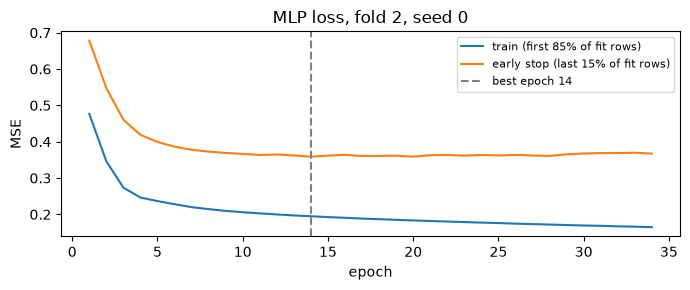

In [8]:
# Training vs early-stopping loss, fold 2, seed 0 (standardised log1p scale)
m0 = mlp_runs[-1]["model"].models_[0]
h = pd.DataFrame(m0.history_)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(h["epoch"], h["train"], label="train (first 85% of fit rows)")
ax.plot(h["epoch"], h["early_stop"], label="early stop (last 15% of fit rows)")
ax.axvline(m0.best_epoch_, color="grey", ls="--", label=f"best epoch {m0.best_epoch_}")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.legend(fontsize=8); ax.set_title("MLP loss, fold 2, seed 0")
fig.tight_layout(); plt.show()

### A.5 · Summary of the chosen models
Skill is 1 − MAE / persistence MAE on the same rows (positive = better than persistence).

In [9]:
parts = [base_fold]
for (fam, fs), name in chosen.items():
    pf = runs[(fam, fs)][0]
    parts.append(pf[pf["candidate"] == name].assign(candidate=f"{fam} ({fs})"))
final_fold = pd.concat(parts, ignore_index=True).rename(columns={"candidate": "model"})
display(final_fold[["model", "fold", "n", "mae", "rmse", "skill_mae", "precision", "recall", "f1", "missed", "events"]].round(3))

final = (final_fold.groupby("model", sort=False)
         .agg(mae=("mae", "mean"), rmse=("rmse", "mean"), skill_mae=("skill_mae", "mean"),
              precision=("precision", "mean"), recall=("recall", "mean"), f1=("f1", "mean"),
              missed=("missed", "sum"), events=("events", "sum")))
display(Markdown("**Mean over the two folds** (missed and events summed)")); display(final.round(3))

,model,fold,n,mae,rmse,skill_mae,precision,recall,f1,missed,events
0,persistence,1,102,57.633,76.677,0.000,0.531,0.515,0.523,16,33
1,persistence,2,101,49.453,63.065,0.000,0.364,0.364,0.364,14,22
2,climatology,1,102,56.978,71.658,0.011,0.571,0.242,0.340,25,33
3,climatology,2,101,52.737,63.636,-0.066,0.250,0.182,0.211,18,22
4,ridge (weather),1,102,50.295,64.628,0.127,0.615,0.242,0.348,25,33
5,ridge (weather),2,101,38.710,48.188,0.217,0.500,0.273,0.353,16,22
6,ridge (no weather),1,102,51.154,66.057,0.112,0.688,0.333,0.449,22,33
7,ridge (no weather),2,101,42.289,51.732,0.145,0.462,0.273,0.343,16,22
8,hgb (weather),1,102,48.808,63.767,0.153,0.586,0.515,0.548,16,33
9,hgb (weather),2,101,38.838,47.617,0.215,0.571,0.364,0.444,14,22


**Mean over the two folds** (missed and events summed)

,mae,rmse,skill_mae,precision,recall,f1,missed,events
model,,,,,,,,
persistence,53.543,69.871,0.000,0.447,0.439,0.443,30,55
climatology,54.858,67.647,-0.028,0.411,0.212,0.275,43,55
ridge (weather),44.502,56.408,0.172,0.558,0.258,0.350,41,55
ridge (no weather),46.722,58.894,0.129,0.575,0.303,0.396,38,55
hgb (weather),43.823,55.692,0.184,0.579,0.439,0.496,30,55
hgb (no weather),47.325,61.241,0.117,0.525,0.379,0.436,34,55
mlp (weather),44.233,56.252,0.175,0.595,0.402,0.480,33,55
mlp (no weather),46.835,59.506,0.127,0.476,0.265,0.338,39,55


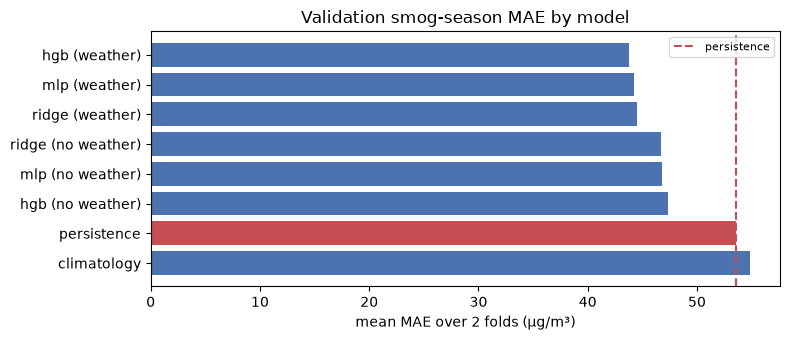

In [10]:
order = final["mae"].sort_values()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(order.index, order.values, color=["#C44E52" if m == "persistence" else "#4C72B0" for m in order.index])
ax.axvline(final.loc["persistence", "mae"], color="#C44E52", ls="--", label="persistence")
ax.invert_yaxis(); ax.set_xlabel("mean MAE over 2 folds (µg/m³)"); ax.legend(fontsize=8)
ax.set_title("Validation smog-season MAE by model")
fig.tight_layout(); plt.show()

### A.6 · Worst days
Rows whose observed PM2.5 is above the 90th percentile of that fold's scored rows. Bias = mean(prediction − observed): negative means underprediction.

In [11]:
worst = final_fold[["model", "fold", "n_extreme", "mae_extreme", "bias_extreme", "skill_mae_extreme"]]
display(worst.round(2))
wm = worst.groupby("model", sort=False)[["mae_extreme", "bias_extreme", "skill_mae_extreme"]].mean()
display(wm.round(2))
learned = wm.drop(index=["persistence", "climatology"])
under = learned.index[learned["bias_extreme"] < 0].tolist()
over = learned.index[learned["bias_extreme"] >= 0].tolist()
beaten = learned.index[learned["skill_mae_extreme"] < 0].tolist()
pw = wm.loc["persistence"]
display(Markdown(
    f"**Worst days:** {len(under)} of {len(learned)} chosen models underpredict the worst days on average "
    f"({', '.join(under) or 'none'})" + (f"; {', '.join(over)} overpredict" if over else "") + ". "
    f"Persistence (itself biased {pw['bias_extreme']:+.0f} µg/m³) has a lower worst-day MAE "
    f"({pw['mae_extreme']:.0f} µg/m³) than {len(beaten)} of {len(learned)} chosen models"
    + (", so persistence wins on the worst days." if len(beaten) == len(learned) else ".")))

,model,fold,n_extreme,mae_extreme,bias_extreme,skill_mae_extreme
0,persistence,1,11,57.82,-39.77,0.00
1,persistence,2,10,52.22,-52.22,0.00
2,climatology,1,11,122.14,-122.14,-1.11
3,climatology,2,10,64.76,-64.76,-0.24
4,ridge (weather),1,11,99.58,-99.58,-0.72
5,ridge (weather),2,10,53.82,-53.82,-0.03
6,ridge (no weather),1,11,89.95,-89.95,-0.56
7,ridge (no weather),2,10,64.92,-64.92,-0.24
8,hgb (weather),1,11,80.46,-80.46,-0.39
9,hgb (weather),2,10,56.75,-56.75,-0.09


,mae_extreme,bias_extreme,skill_mae_extreme
model,,,
persistence,55.02,-46.00,0.00
climatology,93.45,-93.45,-0.68
ridge (weather),76.70,-76.70,-0.38
ridge (no weather),77.44,-77.44,-0.40
hgb (weather),68.60,-68.60,-0.24
hgb (no weather),78.05,-78.05,-0.40
mlp (weather),58.89,-56.49,-0.07
mlp (no weather),74.00,-71.16,-0.34


**Worst days:** 6 of 6 chosen models underpredict the worst days on average (ridge (weather), ridge (no weather), hgb (weather), hgb (no weather), mlp (weather), mlp (no weather)). Persistence (itself biased -46 µg/m³) has a lower worst-day MAE (55 µg/m³) than 6 of 6 chosen models, so persistence wins on the worst days.

### A.7 · Weather ablation (H2): identical rows, each feature set with its own selected configuration
Difference = MAE with weather − MAE without (negative = weather helps).

In [12]:
abl = []
for fam in ("ridge", "mlp"):
    w = final_fold[final_fold["model"] == f"{fam} (weather)"].set_index("fold")
    nw = final_fold[final_fold["model"] == f"{fam} (no weather)"].set_index("fold")
    assert (w["n"] == nw["n"]).all(), "ablation rows differ"
    for k in w.index:
        abl.append({"model": fam, "fold": k, "n": int(w.loc[k, "n"]), "mae weather": w.loc[k, "mae"],
                    "mae no weather": nw.loc[k, "mae"], "difference": w.loc[k, "mae"] - nw.loc[k, "mae"]})
abl = pd.DataFrame(abl)
display(abl.round(2))
mean_diff = abl.groupby("model")["difference"].mean()
display(Markdown("**Mean difference over folds:** " + "; ".join(f"{m} {d:+.2f} µg/m³" for m, d in mean_diff.items())))

,model,fold,n,mae weather,mae no weather,difference
0,ridge,1,102,50.29,51.15,-0.86
1,ridge,2,101,38.71,42.29,-3.58
2,mlp,1,102,48.23,51.34,-3.11
3,mlp,2,101,40.24,42.33,-2.10


**Mean difference over folds:** mlp -2.60 µg/m³; ridge -2.22 µg/m³

### A.8 · Test-winter mildness check (ERA5 weather only, no PM2.5)
Is 2024/25 a mild winter compared with the training winters? Only weather is used; the test PM2.5 stays sealed.

,days,temp_mean,temp_min,temp_range,calm_hours,role
2019/20,121,-15.10,-20.55,11.75,2.95,train
2020/21,120,-17.30,-22.69,11.26,3.67,train
2021/22,120,-15.83,-21.19,11.79,2.62,train
2022/23,120,-18.28,-24.06,12.33,3.02,train
2023/24,121,-18.78,-24.30,11.37,3.12,validation
2024/25,120,-16.29,-22.21,12.44,3.45,test


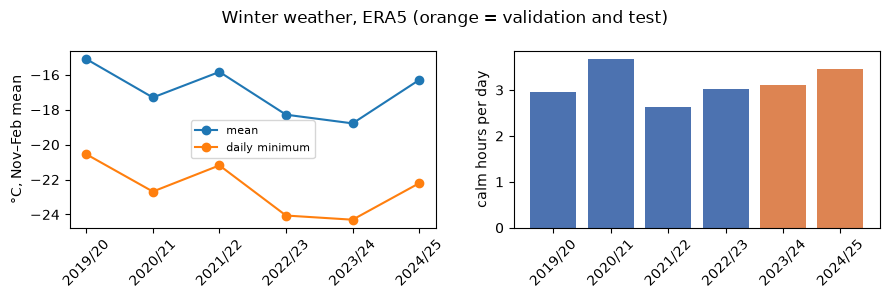

**Mildness:** 2024/25 averaged -16.3 °C (daily minimum -22.2 °C, 3.5 calm hours a day), warmer than 2 of 4 training winters (-18.3 to -15.1 °C). It is not milder than every training winter.

In [13]:
wd = weather.to_daily(weather.load_hourly(cfg))
w = wd[in_months(wd["date"], cfg["smog_months"]).values]
w = w.assign(winter=season_year(w["date"]).values)
w = w[w["winter"].between(2019, 2024)]
mild = w.groupby("winter").agg(days=("date", "size"), temp_mean=("temp_mean", "mean"), temp_min=("temp_min", "mean"),
                               temp_range=("temp_range", "mean"), calm_hours=("calm_hours", "mean"))
mild["role"] = ["train" if s <= 2022 else "validation" if s == 2023 else "test" for s in mild.index]
mild.index = [season_label(s) for s in mild.index]
display(mild.round(2))

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(mild.index, mild["temp_mean"], marker="o", label="mean")
axes[0].plot(mild.index, mild["temp_min"], marker="o", label="daily minimum")
axes[0].set_ylabel("°C, Nov–Feb mean"); axes[0].legend(fontsize=8)
axes[1].bar(mild.index, mild["calm_hours"], color=["#4C72B0" if r == "train" else "#DD8452" for r in mild["role"]])
axes[1].set_ylabel("calm hours per day")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=45)
fig.suptitle("Winter weather, ERA5 (orange = validation and test)"); fig.tight_layout(); plt.show()

tr, te = mild[mild["role"] == "train"], mild[mild["role"] == "test"].iloc[0]
warmer = int((te["temp_mean"] > tr["temp_mean"]).sum())
display(Markdown(
    f"**Mildness:** 2024/25 averaged {te['temp_mean']:.1f} °C (daily minimum {te['temp_min']:.1f} °C, "
    f"{te['calm_hours']:.1f} calm hours a day), warmer than {warmer} of {len(tr)} training winters "
    f"({tr['temp_mean'].min():.1f} to {tr['temp_mean'].max():.1f} °C). "
    + ("It is milder than every training winter." if warmer == len(tr) else
       "It is not milder than every training winter." if warmer else "It is colder than every training winter.")))

### A.9 · Validation winter 2023/24 (fold 2)

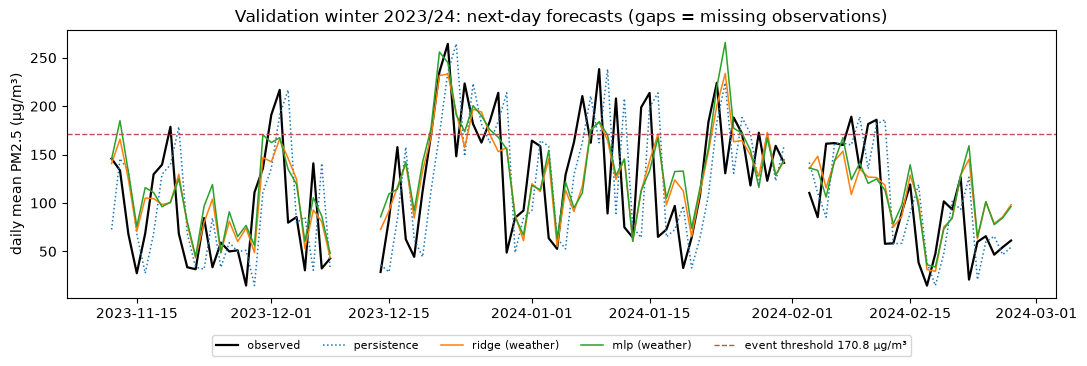

In [14]:
FACT = {"persistence": BASE["persistence"], "climatology": BASE["climatology"]}
FACT.update({f"{fam} ({fs})": CANDS[fam][name] for (fam, fs), name in chosen.items()})
preds = {}
for name, factory in FACT.items():
    if name == "mlp (weather)":                            # already fitted above
        preds[name] = pd.concat([pd.DataFrame({"target_date": r["score_df"]["target_date"].values, "fold": r["fold"],
                                               "y": r["score_df"]["y"].values, "pred": r["pred"]}) for r in mlp_runs],
                                ignore_index=True)
    else:
        cols = cols_nw if name.endswith("(no weather)") else cols_w
        preds[name] = models.predictions(ablation, cols, factory, cfg)

f2 = {n: d[d["fold"] == 2].set_index("target_date") for n, d in preds.items()}
days = pd.date_range(f2["persistence"].index.min(), f2["persistence"].index.max(), freq="D")
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(days, f2["persistence"]["y"].reindex(days), color="k", lw=1.6, label="observed")
for name, style in (("persistence", ":"), ("ridge (weather)", "-"), ("mlp (weather)", "-")):
    ax.plot(days, f2[name]["pred"].reindex(days), ls=style, lw=1.1, label=name)
ax.axhline(thr, color="#C44E52", ls="--", lw=1, label=f"event threshold {thr:g} µg/m³")
ax.set_ylabel("daily mean PM2.5 (µg/m³)"); ax.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_title("Validation winter 2023/24: next-day forecasts (gaps = missing observations)")
fig.tight_layout(); plt.show()

### A.10 · Save
Validation results only; the test split is not scored.

In [15]:
out = ROOT / "outputs" / "results"
out.mkdir(parents=True, exist_ok=True)

sel = [base_fold.assign(family="baseline", features="weather")]
sel += [pf.assign(family=fam, features=fs, chosen=pf["candidate"] == chosen[(fam, fs)]) for (fam, fs), (pf, _) in runs.items()]
pd.concat(sel, ignore_index=True).to_csv(out / "forecast_selection.csv", index=False)

wide = None
for name, d in preds.items():
    d = d.rename(columns={"pred": f"pred_{name}"})
    wide = d if wide is None else wide.merge(d.drop(columns="y"), on=["target_date", "fold"])
wide.to_csv(out / "forecast_val_predictions.csv", index=False)

selected = {
    "run_date": pd.Timestamp.now().strftime("%Y-%m-%d"),
    "protocol": "fit on all training months from core.start; score smog-season targets; select on mean MAE of 2 rolling folds",
    "threshold": {"name": thr_name, "ug_m3": thr, "why": thr_why},
    "chosen": {f"{fam} ({fs})": {"config": name, "mean_mae": float(runs[(fam, fs)][1].loc[name, "mean_mae"])}
               for (fam, fs), name in chosen.items()},
    "baselines_mean_mae": final.loc[["persistence", "climatology"], "mae"].to_dict(),
    "features": {"with_weather": cols_w, "without_weather": cols_nw},
    "dropped_features": {"config_drop_columns": drop, "by_missingness_rule": rule_drop,
                         "missing_share_on_rule_base": share.round(4).to_dict()},
}
(out / "forecast_selected.json").write_text(json.dumps(selected, indent=2), encoding="utf-8")
for f in ("forecast_selection.csv", "forecast_val_predictions.csv", "forecast_selected.json"):
    print("Saved", out / f)

Saved /Users/user/Desktop/neural/outputs/results/forecast_selection.csv
Saved /Users/user/Desktop/neural/outputs/results/forecast_val_predictions.csv
Saved /Users/user/Desktop/neural/outputs/results/forecast_selected.json


## Part B · LSTM and a fair comparison with the MLP

**Goal.** Does a sequence model (LSTM over the last few days) beat the notebook 05 MLP and persistence for next-day PM2.5?

**Protocol (identical to notebook 05).**
1. Fit on every complete training window with target from 2019-07-01, all months.
2. Score on smog-season (Nov–Feb) target days only.
3. Select on the mean MAE of the two rolling folds (fold 1 validates 2021/22, fold 2 validates 2023/24).
4. The test winter (2024/25) is sealed: nothing here fits on, scores or plots its PM2.5.

A window is a run of consecutive complete days ending on issue day D (target D+1); windows never span a gap, so the LSTM scores fewer days than the MLP. Section 3 therefore compares the models only on days both can forecast.

All logic lives in `src/uaq/sequence.py` (reusing `src/uaq/models.py`); this notebook only calls it.

### B.1 · Sequence inputs and the history-days rule
Fixed before training, on availability only (config `forecast.models`): use 14-day histories, unless fold 1 has fewer than `lstm_min_fit_sequences` fit windows, in which case use `lstm_fallback_history_days` for every fold and both feature sets. The no-weather model uses exactly the with-weather windows, so the weather ablation runs on identical days.

In [2]:
feat = pd.read_csv(ROOT / "data" / "processed" / "features_8160.csv", parse_dates=["date", "target_date"])
m = cfg["forecast"]["models"]
cols_w = sequence.sequence_columns(feat, cfg, weather=True)
cols_nw = sequence.sequence_columns(feat, cfg, weather=False)
FEATS = {"weather": cols_w, "no weather": cols_nw}
AVAIL = {"weather": None, "no weather": cols_w}            # shared windows for the ablation
print(f"{len(cols_w)} inputs per day with weather: {cols_w}")
print(f"{len(cols_nw)} inputs per day without weather: {cols_nw}")

T, n1 = sequence.history_days_rule(feat, cfg)
print(f"Fold 1 has {n1} fit windows at {cfg['forecast']['history_days']} days "
      f"(minimum {m['lstm_min_fit_sequences']}) -> history_days = {T}")

18 inputs per day with weather: ['pm_lag0', 'pm_evening', 'pm_last_hour', 'pm_max_hourly', 'doy_sin', 'doy_cos', 'dow_sin', 'dow_cos', 'weekend', 'w_temp_mean', 'w_temp_min', 'w_temp_range', 'w_rh_mean', 'w_pressure_mean', 'w_wind_mean', 'w_calm_hours', 'w_wind_u', 'w_wind_v']
9 inputs per day without weather: ['pm_lag0', 'pm_evening', 'pm_last_hour', 'pm_max_hourly', 'doy_sin', 'doy_cos', 'dow_sin', 'dow_cos', 'weekend']
Fold 1 has 136 fit windows at 14 days (minimum 150) -> history_days = 7


In [3]:
by_date = feat.set_index("date")
folds = {fs: sequence.sequence_folds(feat, FEATS[fs], T, cfg, AVAIL[fs]) for fs in FEATS}
assert all(a[3].equals(b[3]) and a[6].equals(b[6]) for a, b in zip(folds["weather"], folds["no weather"]))
one = pd.Timedelta(days=1)
display(pd.DataFrame([{"features": fs, "fold": k, "fit windows": len(df), "of which smog targets": int(by_date.loc[df, "smog"].sum()),
                       "fit targets from": (df.min() + one).date(), "to": (df.max() + one).date(),
                       "score windows (smog)": len(ds), "score targets from": (ds.min() + one).date(), "to ": (ds.max() + one).date()}
                      for fs in FEATS for k, Xf, yf, df, Xs, ys, ds in folds[fs]]).set_index(["features", "fold"]))

fit windows  of which smog targets fit targets from          to  score windows (smog) score targets from         to 
features   fold                                                                                                                      
weather    1             208                    110       2019-10-24  2021-01-30                    90         2021-11-05  2022-02-11
           2             393                    200       2019-10-24  2022-10-06                    87         2023-11-15  2024-02-27
no weather 1             208                    110       2019-10-24  2021-01-30                    90         2021-11-05  2022-02-11
           2             393                    200       2019-10-24  2022-10-06                    87         2023-11-15  2024-02-27

### B.2 · LSTM grid (5-seed ensembles), with and without weather
Candidates are listed smallest first (fewer units, then more dropout), so a tie (equal to 0.01 µg/m³) goes to the smaller model.

In [4]:
thr_name, thr, thr_why = models.event_threshold(feat, cfg)
print(f"Event threshold (as notebooks 01 and 05): {thr_name} = {thr} µg/m³")
CANDS = {fs: sequence.lstm_candidates(cfg, FEATS[fs]) for fs in FEATS}
SHOW = ["mean_mae", "rmse", "skill_mae", "f1", "missed", "chosen"]
runs = {}
for fs in FEATS:
    runs[fs] = sequence.select_lstm(feat, FEATS[fs], T, CANDS[fs], cfg, thr, AVAIL[fs])
    display(Markdown(f"**lstm, {fs}**")); display(runs[fs][1][SHOW].round(3))
chosen = {fs: s.index[s["chosen"]][0] for fs, (_, s) in runs.items()}
with pd.option_context("display.max_colwidth", 100):
    display(pd.Series({f"lstm ({fs})": c for fs, c in chosen.items()}).to_frame("chosen config"))

Event threshold (as notebooks 01 and 05): train_p75 = 170.8 µg/m³


**lstm, weather**

,mean_mae,rmse,skill_mae,f1,missed,chosen
candidate,,,,,,
lstm hidden=64 dropout=0.2 wd=0.0001 lr=0.001,45.923,59.934,0.185,0.382,40,True
lstm hidden=32 dropout=0.2 wd=0.0001 lr=0.001,46.126,59.934,0.183,0.350,42,False
lstm hidden=32 dropout=0 wd=0.0001 lr=0.001,46.391,60.108,0.177,0.334,42,False
lstm hidden=64 dropout=0 wd=0.0001 lr=0.001,46.410,60.157,0.176,0.391,39,False


**lstm, no weather**

,mean_mae,rmse,skill_mae,f1,missed,chosen
candidate,,,,,,
lstm hidden=32 dropout=0.2 wd=0.0001 lr=0.001,49.134,63.005,0.125,0.353,41,True
lstm hidden=64 dropout=0 wd=0.0001 lr=0.001,49.212,62.941,0.123,0.343,40,False
lstm hidden=32 dropout=0 wd=0.0001 lr=0.001,49.693,63.505,0.113,0.329,41,False
lstm hidden=64 dropout=0.2 wd=0.0001 lr=0.001,49.979,63.600,0.109,0.275,44,False


,chosen config
lstm (weather),lstm hidden=64 dropout=0.2 wd=0.0001 lr=0.001
lstm (no weather),lstm hidden=32 dropout=0.2 wd=0.0001 lr=0.001


In [5]:
# Seed spread of the chosen LSTM (with weather): MAE of each seed and of the 5-seed mean
seeds = m["seeds"]
lstm_runs = list(sequence.run_lstm_folds(feat, cols_w, T, CANDS["weather"][chosen["weather"]], cfg))
rows = []
for r in lstm_runs:
    for s, pr in zip(seeds, r["model"].predict_per_seed(r["X_score"])):
        rows.append({"fold": r["fold"], "seed": s, "mae": metrics.regression(r["y_score"], pr)["mae"]})
    rows.append({"fold": r["fold"], "seed": "5-seed mean", "mae": metrics.regression(r["y_score"], r["pred"])["mae"]})
spread = pd.DataFrame(rows).pivot(index="fold", columns="seed", values="mae")
spread["seed std"] = spread[seeds].std(axis=1)
display(spread.round(2))

seed,0,1,2,3,4,5-seed mean,seed std
fold,,,,,,,
1,55.45,56.12,54.52,55.51,54.36,54.57,0.74
2,38.41,41.99,40.25,35.93,35.34,37.27,2.82


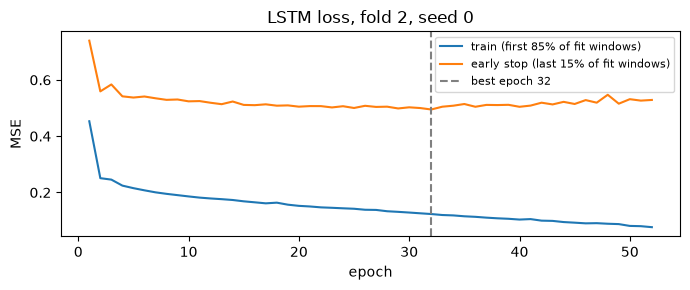

In [6]:
# Training vs early-stopping loss, fold 2, seed 0 (standardised log1p scale)
m0 = lstm_runs[-1]["model"].models_[0]
h = pd.DataFrame(m0.history_)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(h["epoch"], h["train"], label="train (first 85% of fit windows)")
ax.plot(h["epoch"], h["early_stop"], label="early stop (last 15% of fit windows)")
ax.axvline(m0.best_epoch_, color="grey", ls="--", label=f"best epoch {m0.best_epoch_}")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.legend(fontsize=8); ax.set_title("LSTM loss, fold 2, seed 0")
fig.tight_layout(); plt.show()

### B.3 · Fair comparison: persistence, MLP and LSTM on the same days
Score days = target days that have **both** an LSTM window and a notebook 05 MLP prediction, per fold. Event metrics use the notebook 05 threshold; worst days are those above the 90th percentile of observed PM2.5 on these common days.

In [7]:
mlp_file = pd.read_csv(ROOT / "outputs" / "results" / "forecast_val_predictions.csv", parse_dates=["target_date"])
mlp = mlp_file[["target_date", "fold", "pred_mlp (weather)"]].rename(columns={"pred_mlp (weather)": "pred"})
lstm_w = pd.concat([pd.DataFrame({"target_date": r["issue"] + one, "fold": r["fold"], "pred": r["pred"]}) for r in lstm_runs],
                   ignore_index=True)
cmp_fold, cmp_mean = sequence.compare_common_days(feat, {"mlp (weather)": mlp, "lstm (weather)": lstm_w}, cfg, thr)
display(pd.DataFrame({"LSTM windows": lstm_w.groupby("fold").size(), "MLP rows": mlp.groupby("fold").size(),
                      "common days": cmp_fold[cmp_fold["model"] == "persistence"].set_index("fold")["n"]}))
COLS = ["model", "fold", "n", "mae", "rmse", "skill_mae", "precision", "recall", "f1", "missed", "events",
        "mae_extreme", "bias_extreme"]
display(cmp_fold[COLS].round(3))
display(Markdown("**Mean over the two folds** (n, missed and events summed)"))
display(cmp_mean[["n", "mae", "rmse", "skill_mae", "precision", "recall", "f1", "missed", "events",
                  "mae_extreme", "bias_extreme"]].round(3))

,LSTM windows,MLP rows,common days
fold,,,
1,90,102,90
2,87,101,87


,model,fold,n,mae,rmse,skill_mae,precision,recall,f1,missed,events,mae_extreme,bias_extreme
0,persistence,1,90,60.811,79.991,0.000,0.531,0.515,0.523,16,33,48.736,-26.671
1,mlp (weather),1,90,49.747,63.719,0.182,0.684,0.394,0.500,20,33,63.613,-62.771
2,lstm (weather),1,90,54.571,71.682,0.103,0.600,0.182,0.279,27,33,138.284,-138.284
3,persistence,2,87,50.913,64.829,0.000,0.364,0.381,0.372,13,21,44.831,-44.831
4,mlp (weather),2,87,39.928,50.435,0.216,0.643,0.429,0.514,12,21,47.096,-42.536
5,lstm (weather),2,87,37.275,48.186,0.268,0.667,0.381,0.485,13,21,52.219,-52.219


**Mean over the two folds** (n, missed and events summed)

,n,mae,rmse,skill_mae,precision,recall,f1,missed,events,mae_extreme,bias_extreme
model,,,,,,,,,,,
persistence,177,55.862,72.410,0.000,0.447,0.448,0.448,29,54,46.783,-35.751
mlp (weather),177,44.837,57.077,0.199,0.664,0.411,0.507,32,54,55.355,-52.654
lstm (weather),177,45.923,59.934,0.185,0.633,0.281,0.382,40,54,95.252,-95.252


In [8]:
cm = cmp_mean["mae"]
better = lambda a, b: "beats" if cm[a] < cm[b] else "does not beat"            # noqa: E731
display(Markdown(
    f"**On the common days**, the LSTM (mean MAE {cm['lstm (weather)']:.1f} µg/m³) {better('lstm (weather)', 'mlp (weather)')} "
    f"the MLP ({cm['mlp (weather)']:.1f}) and {better('lstm (weather)', 'persistence')} persistence ({cm['persistence']:.1f}); "
    f"per fold the LSTM−MLP difference is "
    + ", ".join(f"fold {k}: {cmp_fold[(cmp_fold['model'] == 'lstm (weather)') & (cmp_fold['fold'] == k)]['mae'].item() - cmp_fold[(cmp_fold['model'] == 'mlp (weather)') & (cmp_fold['fold'] == k)]['mae'].item():+.1f}"
                for k in sorted(cmp_fold["fold"].unique())) + " µg/m³."))

**On the common days**, the LSTM (mean MAE 45.9 µg/m³) does not beat the MLP (44.8) and beats persistence (55.9); per fold the LSTM−MLP difference is fold 1: +4.8, fold 2: -2.7 µg/m³.

### B.4 · Weather ablation for the LSTM (identical windows)
Each feature set with its own selected configuration. Difference = MAE with weather − MAE without (negative = weather helps).

In [9]:
pf = {fs: runs[fs][0][runs[fs][0]["candidate"] == chosen[fs]].set_index("fold") for fs in FEATS}
assert (pf["weather"]["n"] == pf["no weather"]["n"]).all(), "ablation windows differ"
abl = pd.DataFrame({"n": pf["weather"]["n"], "mae weather": pf["weather"]["mae"], "mae no weather": pf["no weather"]["mae"]})
abl["difference"] = abl["mae weather"] - abl["mae no weather"]
display(abl.round(2))
display(Markdown(f"**Mean difference over folds:** {abl['difference'].mean():+.2f} µg/m³"))

,n,mae weather,mae no weather,difference
fold,,,,
1,90,54.57,56.14,-1.57
2,87,37.27,42.13,-4.85


**Mean difference over folds:** -3.21 µg/m³

### B.5 · Validation winter 2023/24 (fold 2), common days

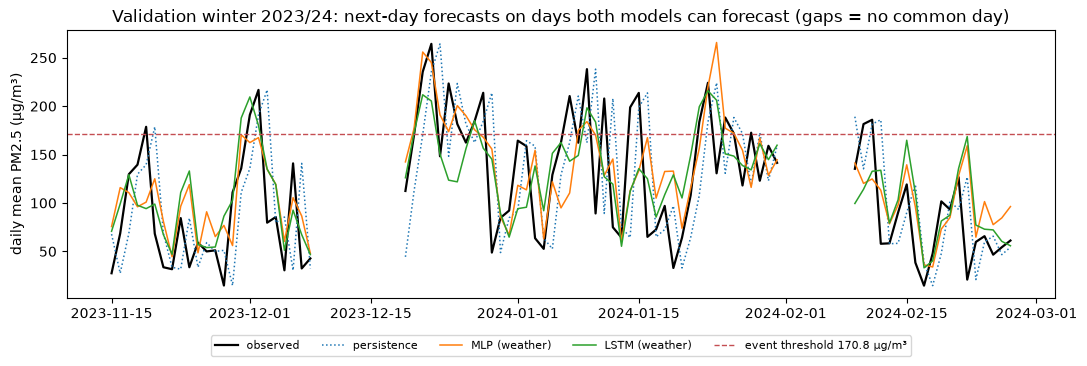

In [10]:
f2 = (lstm_w[lstm_w["fold"] == 2].merge(mlp[mlp["fold"] == 2], on=["target_date", "fold"], suffixes=("_lstm", "_mlp"))
      .set_index("target_date").join(feat.set_index("target_date")[["y", "pm_lag0"]]))
days = pd.date_range(f2.index.min(), f2.index.max(), freq="D")
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(days, f2["y"].reindex(days), color="k", lw=1.6, label="observed")
ax.plot(days, f2["pm_lag0"].reindex(days), ls=":", lw=1.1, label="persistence")
ax.plot(days, f2["pred_mlp"].reindex(days), lw=1.1, label="MLP (weather)")
ax.plot(days, f2["pred_lstm"].reindex(days), lw=1.1, label="LSTM (weather)")
ax.axhline(thr, color="#C44E52", ls="--", lw=1, label=f"event threshold {thr:g} µg/m³")
ax.set_ylabel("daily mean PM2.5 (µg/m³)")
ax.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_title("Validation winter 2023/24: next-day forecasts on days both models can forecast (gaps = no common day)")
fig.tight_layout(); plt.show()

### B.6 · Save
Validation results only; the test split is not scored.

In [11]:
out = ROOT / "outputs" / "results"
sel = [pf_.assign(features=fs, history_days=T, chosen=pf_["candidate"] == chosen[fs]) for fs, (pf_, _) in runs.items()]
pd.concat(sel, ignore_index=True).to_csv(out / "lstm_selection.csv", index=False)

lstm_nw = sequence.predictions_lstm(feat, cols_nw, T, CANDS["no weather"][chosen["no weather"]], cfg, availability_cols=cols_w)
val = (pd.concat([pd.DataFrame({"target_date": r["issue"] + one, "fold": r["fold"], "y": r["y_score"],
                                "pred_lstm (weather)": r["pred"]}) for r in lstm_runs], ignore_index=True)
       .merge(lstm_nw.drop(columns="y").rename(columns={"pred": "pred_lstm (no weather)"}), on=["target_date", "fold"]))
val.to_csv(out / "lstm_val_predictions.csv", index=False)

sel_path = out / "forecast_selected.json"
selected = json.loads(sel_path.read_text(encoding="utf-8"))
selected["lstm"] = {
    "run_date": pd.Timestamp.now().strftime("%Y-%m-%d"),
    "history_days": T,
    "history_days_rule": {"fold1_fit_windows_at_default": n1, "default": cfg["forecast"]["history_days"],
                          "min_fit_sequences": m["lstm_min_fit_sequences"], "fallback": m["lstm_fallback_history_days"]},
    "sequence_columns": {"with_weather": cols_w, "without_weather": cols_nw},
    "chosen": {f"lstm ({fs})": {"config": chosen[fs], "mean_mae": float(runs[fs][1].loc[chosen[fs], "mean_mae"])} for fs in FEATS},
    "fair_comparison_mean_mae": {k: float(v) for k, v in cmp_mean["mae"].items()},
}
sel_path.write_text(json.dumps(selected, indent=2), encoding="utf-8")
for f in ("lstm_selection.csv", "lstm_val_predictions.csv", "forecast_selected.json"):
    print("Saved", out / f)

Saved /Users/user/Desktop/neural/outputs/results/lstm_selection.csv
Saved /Users/user/Desktop/neural/outputs/results/lstm_val_predictions.csv
Saved /Users/user/Desktop/neural/outputs/results/forecast_selected.json
